# 19 · Non-linear effects
The final model (SPEC8 + ZIP3 2017-18 adjustment, `blend_v7`) still has plain linear terms for price and density (per era), drivers (early/late), CAT zone and package. Steps were scanned in `16`, and a depth-1 residual CatBoost found nothing in `final_check.py`, but neither test is strong against smooth curvature or a wrong link. Families tested here (`nonlinear_screen.py`):
- **A. Functional form of SPEC8's linear terms.** Refit with Box-Cox powers, x + x², splines (k 4/6), tercile hinges, quintile bins and one-hot. Statistic: likelihood-ratio p-value over the extra degrees of freedom.
- **B. Smooth main effects.** k = 4 spline blocks (one-hot for ≤ 8 levels) of 33 columns, including price ratios such as price ÷ out-of-fold expected price, in 5 era scopes. Statistic: multi-df score test.
- **C. Smooth interactions.** Centred 3×3 spline-product blocks for 27 pairs × 5 scopes. Score test.
- **D. Link function.** Pregibon η² and Stukel generalized-logistic score tests.

Each family's statistic is the max −log10 p over its candidates. Its chance threshold is the 95th percentile over 200 outcome sets simulated from the fitted SPEC8 plus N(0, 0.16) ZIP3 2017-18 factors. **E (power)** injects known non-linear truths into the simulations.

Precomputed by `nonlinear_screen.py 200 25 nonlinear_results.pkl` (~25 min) and `nonlinear_cvnull.py 40 nonlinear_cvnull.pkl`.

In [1]:
import sys, json, glob, pickle, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
sys.path.insert(0, '.')
import common as C, features as FE, formula as FM, formula_steps as FS, nonlinear_screen as NS
from formula_steps import t
R = pickle.load(open('nonlinear_results.pkl', 'rb')); real, null = R['real'], R['null']
L, y, lab, hold = FS.L, FS.y, FS.lab, FS.hold

## 1. Calibration
Score statistics against exact likelihood-ratio refits; and the false-pass rate of thresholds set on null simulations 1–100, applied to simulations 101–200.

In [2]:
eta, p, dev0 = NS.irls(NS.X0, NS.y); Xs = NS._std(NS.X0); Minv = np.linalg.pinv(Xs.T @ (Xs * (p * (1 - p))[:, None]))
rows = []
for kind, name, sc in [('B', 'CAT_ZONE', '2016'), ('B', 'VEH_SAFETY_MIN', '2016'), ('B', 'log price / expected (OOF)', 'late'),
                       ('B', 'CREDIT_SCORE', 'late'), ('C', 'DEN_KM2 x CREDIT_SCORE', '2015'), ('C', 'QUOTED_AMT x CAT_ZONE', 'late')]:
    Xb = (NS.B_CANDS if kind == 'B' else NS.C_CANDS)[name] * NS.MASKS[sc][:, None]
    chi, df = NS.score_block(Xb, Xs, p, NS.y, Minv)
    rows.append({'candidate': name, 'scope': sc, 'df': df, 'score χ²': chi, 'LR': dev0 - NS.irls(np.hstack([NS.X0, Xb]), NS.y)[2]})
display(pd.DataFrame(rows).round(2))
F = pd.DataFrame([n['family'] for n in null]); T = F.quantile(.95)
print('held-out false-pass rate:', (F.iloc[100:] > F.iloc[:100].quantile(.95)).mean().round(3).to_dict())

,candidate,scope,df,score χ²,LR
0,CAT_ZONE,2016,4,14.25,14.45
1,VEH_SAFETY_MIN,2016,5,13.64,14.01
2,log price / expected (OOF),late,4,11.19,10.22
3,CREDIT_SCORE,late,4,7.15,7.96
4,DEN_KM2 x CREDIT_SCORE,2015,7,25.07,24.99
5,QUOTED_AMT x CAT_ZONE,late,9,17.95,17.79


held-out false-pass rate: {'A': 0.04, 'B': 0.01, 'C': 0.05, 'D': 0.05}


## 2. Family results

In [3]:
pd.DataFrame({'real max −log10 p': pd.Series(real['family']), 'chance threshold (95%)': T,
              'p (share of nulls ≥ real)': [(F[k] >= real['family'][k]).mean() for k in 'ABCD']},
             index=list('ABCD')).rename(index={'A': 'A functional form', 'B': 'B smooth main effects', 'C': 'C smooth interactions',
                                               'D': 'D link'}).round(3)

,real max −log10 p,chance threshold (95%),p (share of nulls ≥ real)
A functional form,1.870,2.066,0.100
B smooth main effects,2.185,3.832,0.585
C smooth interactions,3.132,4.880,0.245
D link,0.707,1.234,0.230


**No family passes.** Score and LR agree within ~10%, and the thresholds give ~5% false passes on held-out simulations, so the test is calibrated.

## 3. A · Functional form by term

In [4]:
AT = pd.DataFrame([n['A term'] for n in null])
display(pd.DataFrame({'real': pd.Series(real['A term']), 'term threshold (95%)': AT.quantile(.95),
                      'p': [(AT[k] >= real['A term'][k]).mean() for k in AT]}).round(3))
real['A'].sort_values('-log10 p', ascending=False).head(10).round(3).style.hide(axis='index')

,real,term threshold (95%),p
CAT_ZONE,1.644,1.538,0.040
DEN_KM2,1.870,1.616,0.040
NUM_DRIVERS,1.330,1.639,0.095
PKG_ORDINAL_IMP,1.028,1.167,0.100
QUOTED_AMT,0.136,1.556,0.955


term,variant,LR,extra df,-log10 p
DEN_KM2,x + x^2,10.698000,3,1.870000
CAT_ZONE,one-hot,9.561000,3,1.644000
NUM_DRIVERS,"one-hot (1,2,3,4,5+)",12.775000,6,1.330000
DEN_KM2,boxcox 1.5,3.735000,0,1.273000
PKG_ORDINAL_IMP,one-hot,6.398000,3,1.028000
CAT_ZONE,x + x^2,1.872000,1,0.766000
DEN_KM2,hinge terciles,7.787000,6,0.595000
NUM_DRIVERS,x + x^2,1.222000,2,0.265000
QUOTED_AMT,spline k4,8.660000,12,0.136000
QUOTED_AMT,hinge terciles,3.534000,6,0.131000


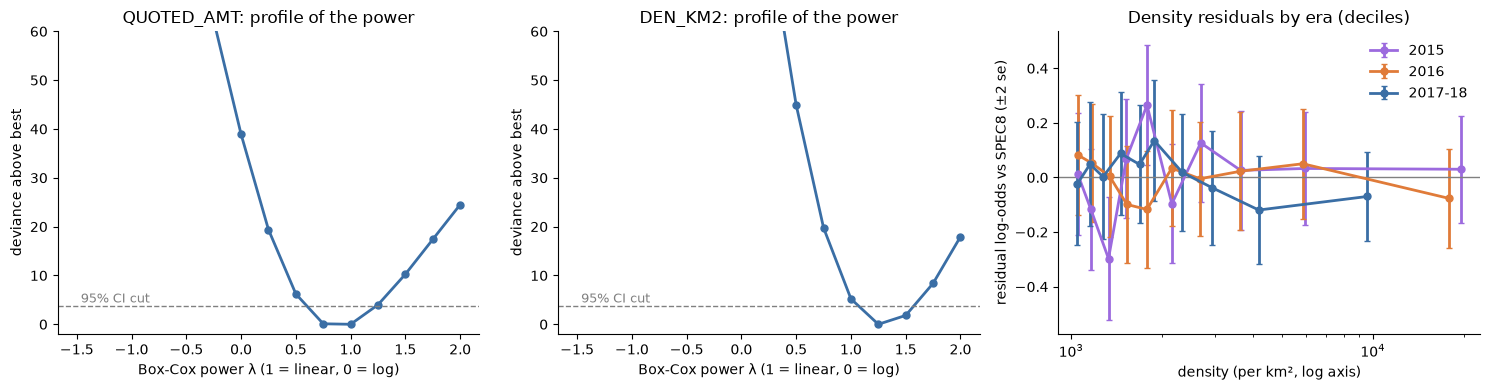

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (c, s) in zip(ax[:2], real['boxcox'].items()):
    d = s - s.min(); a.plot(d.index, d.values, lw=2, marker='o', ms=5, color='#3a6ea5')
    a.axhline(3.84, color='grey', lw=1, ls='--'); a.text(d.index[0], 3.84, ' 95% CI cut', va='bottom', color='grey', fontsize=9)
    a.set_ylim(-2, 60); a.set_xlabel('Box-Cox power λ (1 = linear, 0 = log)'); a.set_ylabel('deviance above best'); a.set_title(f'{c}: profile of the power')
    a.spines[['top', 'right']].set_visible(False)
eta, p, _ = NS.irls(NS.X0, NS.y); w, r = p * (1 - p), NS.y - p; x = NS._fill('DEN_KM2')
for m, col in (('2015', '#9c6ade'), ('2016', '#e07b39'), ('late', '#3a6ea5')):
    k = NS.MASKS[m] > 0; q = pd.qcut(x[k], 10)
    g = pd.DataFrame({'q': q, 'r': r[k], 'w': w[k], 'x': x[k]}).groupby('q', observed=True).agg(x=('x', 'median'), r=('r', 'sum'), w=('w', 'sum'))
    ax[2].errorbar(g.x, g.r / g.w, yerr=2 / np.sqrt(g.w), lw=2, marker='o', ms=5, capsize=2, color=col, label={'late': '2017-18'}.get(m, m))
ax[2].axhline(0, color='grey', lw=1); ax[2].set_xscale('log'); ax[2].set_xlabel('density (per km², log axis)'); ax[2].set_ylabel('residual log-odds vs SPEC8 (±2 se)')
ax[2].set_title('Density residuals by era (deciles)'); ax[2].legend(frameon=False); ax[2].spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('figures/19_functional_form.png', dpi=130, bbox_inches='tight'); plt.show()

**Reading:**
- **Price is exactly linear** (λ = 1; log costs 39 deviance).
- **Density is slightly convex:** best λ = 1.25, and linear is 5.2 deviance worse. Log costs 119, and any cap costs ≥ 77 in 2017-18. Its term p = 0.04, as is CAT zone's (one-hot), but across 5 terms the family p is 0.10.
- **Rejected by direct refits in 2017-18:** log, sqrt and 1/x density, caps at any level, and steps on top of the linear term (best LR 9 over 95 cuts, chance level).

## 4. B, C, D · Strongest candidates (all below their family thresholds)

In [6]:
display(real['B'].sort_values('-log10 p', ascending=False).head(8).round(3).style.hide(axis='index').set_caption(f"B threshold {T['B']:.2f}"))
display(real['C'].sort_values('-log10 p', ascending=False).head(8).round(3).style.hide(axis='index').set_caption(f"C threshold {T['C']:.2f}"))
real['D'].round(3).style.hide(axis='index').set_caption(f"D threshold {T['D']:.2f}")

candidate,scope,chi2,df,-log10 p
CAT_ZONE,2016,14.252000,4,2.185000
VEH_SAFETY_MIN,2016,13.635000,5,1.742000
VEH_SAFETY_MIN,early,11.577000,4,1.682000
log price / expected (OOF),late,11.194000,4,1.611000
log price / expected (OOF),all,11.117000,4,1.597000
CAT_ZONE,all,9.304000,3,1.593000
NUM_DRIVERS,late,9.843000,4,1.365000
DRV_SAFETY_MEAN,all,9.725000,4,1.344000


candidate,scope,chi2,df,-log10 p
DEN_KM2 x CREDIT_SCORE,2015,25.069000,7,3.132000
QUOTED_AMT x CAT_ZONE,late,17.946000,9,1.446000
QUOTED_AMT x CAT_ZONE,all,17.723000,9,1.414000
DEN_KM2 x CREDIT_SCORE,early,14.769000,7,1.408000
DEN_KM2 x PKG_ORDINAL_IMP,2015,17.459000,9,1.377000
DEN_KM2 x NUM_DRIVERS,2016,17.429000,9,1.373000
DRV_AGE_MEAN x CAT_ZONE,2015,16.720000,9,1.273000
CAT_ZONE x PKG_ORDINAL_IMP,all,16.713000,9,1.272000


test,chi2,df,-log10 p
Pregibon eta^2,1.670000,1,0.707000
Stukel (2 terms),3.053000,2,0.663000


## 5. E · Power: detection rate of injected non-linear truths
Injected component = the part orthogonal to SPEC8's design, scaled to the given log-odds sd; `oracle gain` = AUC gained by knowing it (25 simulations each).

In [7]:
P = pd.DataFrame(R['power']); fam = pd.DataFrame(list(P.family))
for k in 'ABC':
    P[f'{k} detects'] = (fam[k] > T[k]).values
P['any family'] = P[['A detects', 'B detects', 'C detects']].any(axis=1)
P.groupby(['injection', 'sd'])[['oracle gain', 'A detects', 'B detects', 'C detects', 'any family']].mean().round(4)

oracle gain  A detects  B detects  C detects  \
injection           sd                                                  
credit curve (late) 0.1       0.0008       0.32       0.52       0.12   
                    0.2       0.0035       0.88       1.00       0.84   
                    0.3       0.0081       1.00       1.00       1.00   
log price (per era) 0.1       0.0008       0.84       0.40       0.08   
                    0.2       0.0028       1.00       1.00       1.00   
                    0.3       0.0060       1.00       1.00       1.00   
price x credit      0.1       0.0008       0.44       0.32       0.08   
                    0.2       0.0028       1.00       1.00       1.00   
                    0.3       0.0063       1.00       1.00       1.00   
sqrt density (late) 0.1       0.0010       1.00       0.92       0.00   
                    0.2       0.0039       1.00       1.00       0.64   
                    0.3       0.0089       1.00       1.00       1.00   

                         any family  
injection           sd               
credit curve (late) 0.1        0.64  
                    0.2        1.00  
                    0.3        1.00  
log price (per era) 0.1        0.88  
                    0.2        1.00  
                    0.3        1.00  
price x credit      0.1        0.56  
                    0.2        1.00  
                    0.3        1.00  
sqrt density (late) 0.1        1.00  
                    0.2        1.00  
                    0.3        1.00

**Non-linear effects worth ≥ +0.002 AUC are detected every time; those worth ~+0.001 are detected 56–100% of the time.** So anything missed here is worth < ~0.001 AUC.

## 6. Density² per era: cross-validated check
The strongest family-A variant was density + density² per era. It's tested in CV and calibrated against the same CV comparison on 40 null simulations (seed-0 folds, formula only). The null comparison uses the best of the top 4 A variants, to account for picking it.

In [8]:
CN = pickle.load(open('nonlinear_cvnull.pkl', 'rb')); S = pd.DataFrame(CN['sims']); D = S.drop(columns='SPEC8').sub(S.SPEC8, axis=0)
rv = pd.Series(CN['real']); dr = rv.drop('SPEC8') - rv.SPEC8
display(pd.DataFrame({'real Δ AUC': dr, 'null mean': D.mean(), 'null sd': D.std(), 'share of nulls ≥ real': [(D[c] >= dr[c]).mean() for c in D]}).round(5))
print(f"best of 4 in nulls: 95% = {D.max(axis=1).quantile(.95):+.5f}; share ≥ real best ({dr.max():+.5f}) = {(D.max(axis=1) >= dr.max()).mean():.3f}")

,real Δ AUC,null mean,null sd,share of nulls ≥ real
density^2 per era,0.00045,-0.00008,0.00018,0.025
CAT one-hot,-0.00013,-0.00027,0.00028,0.350
drivers one-hot,-0.00003,-0.00040,0.00027,0.100
package one-hot,-0.00052,-0.00039,0.00027,0.575


best of 4 in nulls: 95% = +0.00033; share ≥ real best (+0.00045) = 0.025


In [9]:
late = (L.ERA.astype(str) == '2017-18').to_numpy(); z3 = L.ZIP_CD.astype(str).str[:3].to_numpy(); FOLDS = C.folds(lab); TAU2 = 0.03
def fit_z3(spec, Ltr, ytr, lt, zt):
    m = FM.Formula(spec, 0.1, '2era').fit(Ltr, ytr); p = m.predict(Ltr)
    r = pd.DataFrame({'g': zt[lt], 'r': (ytr - p)[lt], 'w': (p * (1 - p))[lt]}).groupby('g').sum()
    return m, r.r / (r.w + 1 / TAU2)
def pred_z3(m, eff, D, lt, zt):
    return 1 / (1 + np.exp(-(m.decision(D) + np.where(lt, pd.Series(zt).map(eff).fillna(0).to_numpy(), 0))))
def final_oof(spec):
    P = np.zeros((3, len(y)))
    for s, k, tr, va in FOLDS:
        m, eff = fit_z3(spec, L.iloc[tr], y[tr], late[tr], z3[tr]); P[s, va] = pred_z3(m, eff, L.iloc[va], late[va], z3[va])
    return P
PC = json.load(open('params_cats.json'))
cb = C.cv_score('cats15___copies__ohm_10', FE.add_cats(FE.add_static(lab)), PC['features'], 'cb', PC['params'])['oof_all']
aucs = lambda Q: np.array([roc_auc_score(y[va], Q[s, va]) for s, k, tr, va in FOLDS])
P8, P9 = final_oof(FS.SPEC8), final_oof(FS.SPEC9)
r8, r9 = FS.run4(FS.SPEC8, seeds=(0, 1, 2)), FS.run4(FS.SPEC9, seeds=(0, 1, 2), name='fx_spec9')
cands = {'SPEC8': (r9['oof_all'], r8['oof_all']), 'SPEC8 + ZIP3 (final)': (P9, P8), 'blend 0.9/0.1 (blend_v7 → blend_v8)': (0.9 * P9 + 0.1 * cb, 0.9 * P8 + 0.1 * cb)}
rows = {}
for n, (Q9, Q8) in cands.items():
    d = aucs(Q9) - aucs(Q8)
    rows[n] = {'AUC with density² (15)': aucs(Q9).mean(), 'AUC without': aucs(Q8).mean(), 'Δ seed 0': d[:5].mean(), 'se 0': d[:5].std() / 5 ** .5,
               'Δ seeds 1–2': d[5:].mean(), 'se 1–2': d[5:].std() / 10 ** .5,
               'top-decile with': np.mean([C.top_decile_precision(y, Q9[s]) for s in range(3)])}
pd.DataFrame(rows).T.style.format('{:+.5f}', subset=['Δ seed 0', 'se 0', 'Δ seeds 1–2', 'se 1–2']).format('{:.5f}', subset=['AUC with density² (15)', 'AUC without']).format('{:.1%}', subset=['top-decile with'])

,AUC with density² (15),AUC without,Δ seed 0,se 0,Δ seeds 1–2,se 1–2,top-decile with
SPEC8,0.72511,0.72463,+0.00045,+0.00019,+0.00050,+0.00012,31.8%
SPEC8 + ZIP3 (final),0.72550,0.72511,+0.00032,+0.00017,+0.00042,+0.00010,31.8%
blend 0.9/0.1 (blend_v7 → blend_v8),0.72567,0.72531,+0.00028,+0.00018,+0.00040,+0.00010,31.9%


In [10]:
m9 = FM.Formula(FS.SPEC9, 0.1, '2era').fit(L, y); ct = m9.coef_table(); ct[ct.index.str.contains('DEN')]

,coef,coef (std)
term,,
DEN_KM2:linear @2015,3.570420e-05,0.150011
DEN_KM2:linear @2016,2.385052e-05,0.101367
DEN_KM2:linear @2017-18,5.743741e-05,0.164995
DEN_KM2_SQ:linear @2015,-5.070419e-10,-0.071090
DEN_KM2_SQ:linear @2016,2.941905e-10,0.041403
DEN_KM2_SQ:linear @2017-18,2.012177e-09,0.149176


## 7. Submissions

In [11]:
H = FM.prep(hold); lh = (H.ERA.astype(str) == '2017-18').to_numpy(); zh = H.ZIP_CD.astype(str).str[:3].to_numpy()
m, eff = fit_z3(FS.SPEC9, L, y, late, z3); ph = pred_z3(m, eff, H, lh, zh)
cbp = pd.read_csv(sorted(glob.glob('../submissions/catboost_cats5_*.csv'))[-1]); assert (cbp.POLICY_ID.values == hold.POLICY_ID.values).all()
v7 = pd.read_csv(sorted(glob.glob('../submissions/blend_v7_*.csv'))[-1])
out = {'formula_v6': C.write_submission('formula_v6', hold, ph), 'blend_v8': C.write_submission('blend_v8', hold, 0.9 * ph + 0.1 * cbp.CONVERT_IND_PRED.to_numpy())}
json.dump({'spec': FS.SPEC9, 'C': 0.1, 'intercepts': '2era', 'zip3_late_offset_tau2': TAU2, 'blend_weight_formula': 0.9}, open('formula_v6_spec.json', 'w'), indent=1)
from scipy.stats import spearmanr
print(out, '| rank corr with blend_v7:', round(spearmanr(pd.read_csv(out['blend_v8']).CONVERT_IND_PRED, v7.CONVERT_IND_PRED)[0], 5))

{'formula_v6': PosixPath('/Users/joerussell/Desktop/PROJECTS/competitions/travelers-umc/submissions/formula_v6_20261031.csv'), 'blend_v8': PosixPath('/Users/joerussell/Desktop/PROJECTS/competitions/travelers-umc/submissions/blend_v8_20261031.csv')} | rank corr with blend_v7: 0.99891


## Conclusions
- **No non-linear family passes its chance threshold:** functional form p = 0.10, smooth main effects 0.59, smooth interactions 0.25, link 0.23. Power is high: injected effects worth ≥ +0.002 AUC are always found.
- **The linear forms are right:**
  - price is exactly linear (Box-Cox λ = 1);
  - in 2017-18, log density, caps and steps are all strongly rejected;
  - price-competitiveness ratios (price ÷ expected price, per vehicle, per driver, ÷ state median) add nothing;
  - the logistic link fits.
- **One weak signal: density is slightly convex** (best λ 1.25; density² per era, term p = 0.04).
  - In CV it adds +0.0004 ± 0.0001 AUC on seeds 1–2 in the final blend. Only 2.5% of null simulations gain that much, even picking the best of 4 variants.
  - Adopted as **`SPEC9`** → `formula_v6`, `blend_v8` (meets the > 2 se rule).
  - It's a small, moderately-supported change: it could be chance given the family p of 0.10, and if so it costs ~0.0001. Its expected public-leaderboard effect is far below the leaderboard noise (sd 0.013).